# Flywheel speed regulation under a load torque

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/05-motor-load-rejection/notebook.ipynb)

## Goal
A synthetic DC motor drives a flywheel with $R=2\,\Omega$, $L=0.02\,\mathrm{H}$, $J=0.01\,\mathrm{kg\,m^2}$, $b=0.02\,\mathrm{N\,m\,s/rad}$ and $k_t=k_e=0.1$ in consistent SI units. Derive the voltage-to-speed and opposing-load-to-speed transfers. Compare proportional gain $k_p=0.8$ with PI gains $k_p=0.8$, $k_i=1.6$ for reference $5\,\mathrm{rad/s}$ and load $0.03\,\mathrm{N\,m}$ applied at $t=4\,\mathrm{s}$. Explain the benefits and limits of integral action.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/05-motor-load-rejection/figures/physical-system.png)

A voltage-driven motor converts armature current into shaft torque. The rotor and external brake introduce inertia, friction and load torque. The illustrative cutaway does not add magnetic saturation or friction to the stated linear model.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/05-motor-load-rejection/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/05-motor-load-rejection/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/05-motor-load-rejection/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/05-motor-load-rejection/figures/system-diagram.png)

Outer PI speed regulation around the electromechanical motor. The inner back-emf path and opposing load torque have explicit negative signs.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Electromechanical balance
Let $i$ be armature current, $\omega$ angular speed, $v$ voltage and $d$ opposing load torque. The equations are

$$
L\dot i=v-Ri-k_e\omega,\qquad J\dot\omega=k_t i-b\omega-d.
$$

Eliminating current yields the common denominator $D(s)=(Ls+R)(Js+b)+k_tk_e$ and

$$
G_v(s)=\frac{k_t}{D(s)},\qquad G_d(s)=-\frac{Ls+R}{D(s)}.
$$

Numerically $D(s)=0.0002s^2+0.0204s+0.05$ and $G_v(0)=2$ (rad/s)/V.
### Closed-loop paths
For $v=C(s)(r-\omega)$, superposition gives

$$
\Omega=\frac{C G_v}{1+C G_v}R+\frac{G_d}{1+C G_v}D_{load}.
$$

With proportional control, the final speed is $(K_pG_v(0)r+G_d(0)d)/(1+K_pG_v(0))$. Substitution gives $(8-1.2)/2.6=2.61538$ rad/s after the load arrives.
### Integral action and stability
For $C=0.8+1.6/s$, the characteristic polynomial is

$$
0.0002s^3+0.0204s^2+0.13s+0.16.
$$

Its positive coefficients satisfy $0.0204(0.13)>0.0002(0.16)$, so the cubic is Hurwitz. A stable loop with integral action rejects a constant load and tracks the constant reference in this ideal unsaturated model. The required steady voltage is not zero: equilibrium requires $i=(br+d)/k_t=1.3$ A and $v=Ri+k_er=3.1$ V.
### Limits
Voltage and current limits, magnetic saturation, brush friction, heating and sensor noise are omitted. Integral action cannot provide an unavailable actuator voltage.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
R,L,J,b,kt,ke=2.,.02,.01,.02,.1,.1
den=np.polymul([L,R],[J,b]); den[-1]+=kt*ke
voltage_path=ct.tf([kt],den); disturbance_path=ct.tf([-L,-R],den)
controllers=[('P',ct.tf([.8],[1])),('PI',ct.tf([.8,1.6],[1,0]))]
time=np.linspace(0,18,9001); load=.03*(time>=4)
responses=[]
for label,controller in controllers:
    closed=ct.feedback(controller*voltage_path,1)
    disturbance=ct.feedback(disturbance_path,0) / (1+controller*voltage_path)
    disturbance=ct.minreal(disturbance,verbose=False)
    assert np.all(np.real(ct.poles(closed))<0)
    _,tracking=ct.step_response(5*closed,time)
    rejected=ct.forced_response(disturbance,time,load).outputs
    speed=tracking+rejected; responses.append((label,speed))
    print(f'{label}: final simulated speed={speed[-1]:.6f} rad/s')
assert abs(responses[0][1][-1]-6.8/2.6)<1e-5
assert abs(responses[1][1][-1]-5)<1e-4
print('Required ideal steady voltage at 5 rad/s with load: 3.100000 V')


P: final simulated speed=2.615385 rad/s


PI: final simulated speed=5.000000 rad/s
Required ideal steady voltage at 5 rad/s with load: 3.100000 V


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

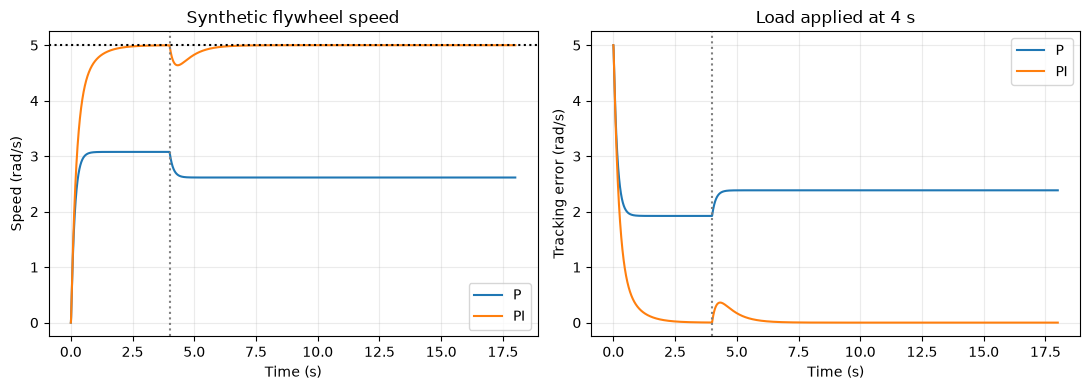

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,speed in responses:
    axes[0].plot(time,speed,label=label); axes[1].plot(time,5-speed,label=label)
axes[0].axhline(5,color='black',ls=':'); axes[0].set(xlabel='Time (s)',ylabel='Speed (rad/s)',title='Synthetic flywheel speed')
axes[1].set(xlabel='Time (s)',ylabel='Tracking error (rad/s)',title='Load applied at 4 s')
for ax in axes: ax.axvline(4,color='gray',ls=':'); ax.legend()
fig.tight_layout()

plt.show()

## Interpret and extend
Track the disturbance entry point as carefully as the reference path. Zero ideal steady error is conditional on stability and actuator feasibility.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)